In [1]:
# the necessary libraries installed
import os
#import cv2
#import pafy
import math
import random
import numpy as np
import datetime as dt
import tensorflow as tf
from collections import deque
import matplotlib.pyplot as plt

#from moviepy.editor import *
%matplotlib inline

from sklearn.model_selection import train_test_split

from tensorflow.keras.layers import *
#from tensorflow.keras.models import Model
#from tensorflow.keras.layers import Input, ConvLSTM2D, MaxPooling3D, TimeDistributed, Dropout, Flatten, Dense
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import plot_model

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau


from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Flatten, Dropout, GlobalAveragePooling2D
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

In [2]:
#SET THE RANDOM AS CONSISTENT VALUE
seed_constant = 27
np.random.seed(seed_constant)
random.seed(seed_constant)
tf.random.set_seed(seed_constant)

In [3]:
# Set the dataset path as a string
dataset_path = r'C:\Users\pc\Desktop\DeepLearning\DeepLearningAlzheimer\Final_Journal_Simulation\Dataset\ADNI\Final_Dataset\Enhanced_Augmented_6_Class (Different Variations)\AD vs CN vs EMCI vs LMCI'  # The path to your dataset directory

# Optional: List the types of labels/classes (directories within dataset_path)
label_types = os.listdir(dataset_path)
print("Label types:", label_types)

Label types: ['AD', 'CN', 'EMCI', 'LMCI']


In [4]:


# Hyperparameters
BATCH_SIZE = 16
TARGET_SIZE = (224, 224)
EPOCHS = 20
NUM_CLASSES = 4

datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,           # less aggressive
    zoom_range=0.2,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    validation_split=0.2
)

train_generator = datagen.flow_from_directory(
    dataset_path,
    target_size=TARGET_SIZE,
    batch_size=16,             # Lower batch size for limited VRAM
    class_mode='categorical',
    subset='training'
)

validation_generator = datagen.flow_from_directory(
    dataset_path,
    target_size=TARGET_SIZE,
    batch_size=16,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

# ==========================================
# 2. MODEL ARCHITECTURE (AlzNet)
# ==========================================
def residual_separable_block(tensor, filters, strides=1):
    shortcut = tensor
    if strides != 1 or tensor.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, (1, 1), strides=strides, padding='same', use_bias=False)(tensor)
        shortcut = layers.BatchNormalization()(shortcut)

    x = layers.SeparableConv2D(filters, (3, 3), strides=strides, padding='same', use_bias=False)(tensor)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    x = layers.SeparableConv2D(filters, (3, 3), strides=1, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)

    x = layers.Add()([x, shortcut])
    x = layers.Activation('relu')(x)
    return x

def create_alznet_model(input_shape=(224, 224, 3), num_classes=4):
    inputs = layers.Input(shape=input_shape, name='input_image')

    # Stem
    x = layers.Conv2D(32, (3, 3), strides=(2, 2), padding='same', use_bias=False)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    # Feature Extractor
    x = residual_separable_block(x, 64, strides=2)   
    x = residual_separable_block(x, 128, strides=2)  
    x = residual_separable_block(x, 256, strides=2)  
    x = residual_separable_block(x, 256, strides=1)  

    # Classification Head
    x = layers.GlobalAveragePooling2D(name='global_pool')(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(num_classes, activation='softmax', name='predictions')(x)

    # Renamed model to AlzNet
    return models.Model(inputs, outputs, name="AlzNet")

model = create_alznet_model(input_shape=(224, 224, 3), num_classes=NUM_CLASSES)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)
model.summary()

Found 32000 images belonging to 4 classes.
Found 8000 images belonging to 4 classes.
Model: "AlzNet"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_image (InputLayer)       [(None, 224, 224, 3  0           []                               
                                )]                                                                
                                                                                                  
 conv2d (Conv2D)                (None, 112, 112, 32  864         ['input_image[0][0]']            
                                )                                                                 
                                                                                                  
 batch_normalization (BatchNorm  (None, 112, 112, 32  128        ['conv2d[0][0]']                 
 alizati

In [5]:
# Train the model
history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // train_generator.batch_size,  # Number of steps per epoch
    validation_data=validation_generator,
    validation_steps=validation_generator.samples // validation_generator.batch_size,  # Validation steps
    epochs=20,  # Number of epochs to train for
    #callbacks=[checkpoint, early_stopping]  # Include any callbacks
)


Epoch 1/20
2000/2000 [==============================] - 437s 216ms/step - loss: 1.2638 - accuracy: 0.3904 - val_loss: 1.2328 - val_accuracy: 0.3989
Epoch 2/20
2000/2000 [==============================] - 527s 263ms/step - loss: 1.1466 - accuracy: 0.4593 - val_loss: 1.1343 - val_accuracy: 0.4894
Epoch 3/20
2000/2000 [==============================] - 527s 264ms/step - loss: 1.0758 - accuracy: 0.5123 - val_loss: 1.1214 - val_accuracy: 0.4873
Epoch 4/20
2000/2000 [==============================] - 527s 263ms/step - loss: 0.9778 - accuracy: 0.5768 - val_loss: 1.1112 - val_accuracy: 0.5409
Epoch 5/20
2000/2000 [==============================] - 527s 264ms/step - loss: 0.8694 - accuracy: 0.6356 - val_loss: 1.0289 - val_accuracy: 0.5975
Epoch 6/20
2000/2000 [==============================] - 528s 264ms/step - loss: 0.7552 - accuracy: 0.6916 - val_loss: 0.7163 - val_accuracy: 0.7124
Epoch 7/20
2000/2000 [==============================] - 527s 264ms/step - loss: 0.6502 - accuracy: 0.7372 - val_

In [6]:
# ==========================================
# 3. DIRECTORIES & CALLBACKS
# ==========================================
model_name = "AlzNetV1"
save_dir = "H5 files"
figures_dir = os.path.join("Figures", model_name)

os.makedirs(save_dir, exist_ok=True)
os.makedirs(figures_dir, exist_ok=True)

In [7]:
# Save the final model
save_path = os.path.join(save_dir, f"{model_name}.h5")
model.save(save_path)
print(f"\n✅ Model successfully saved to: {save_path}")


✅ Model successfully saved to: H5 files\AlzNetV1.h5


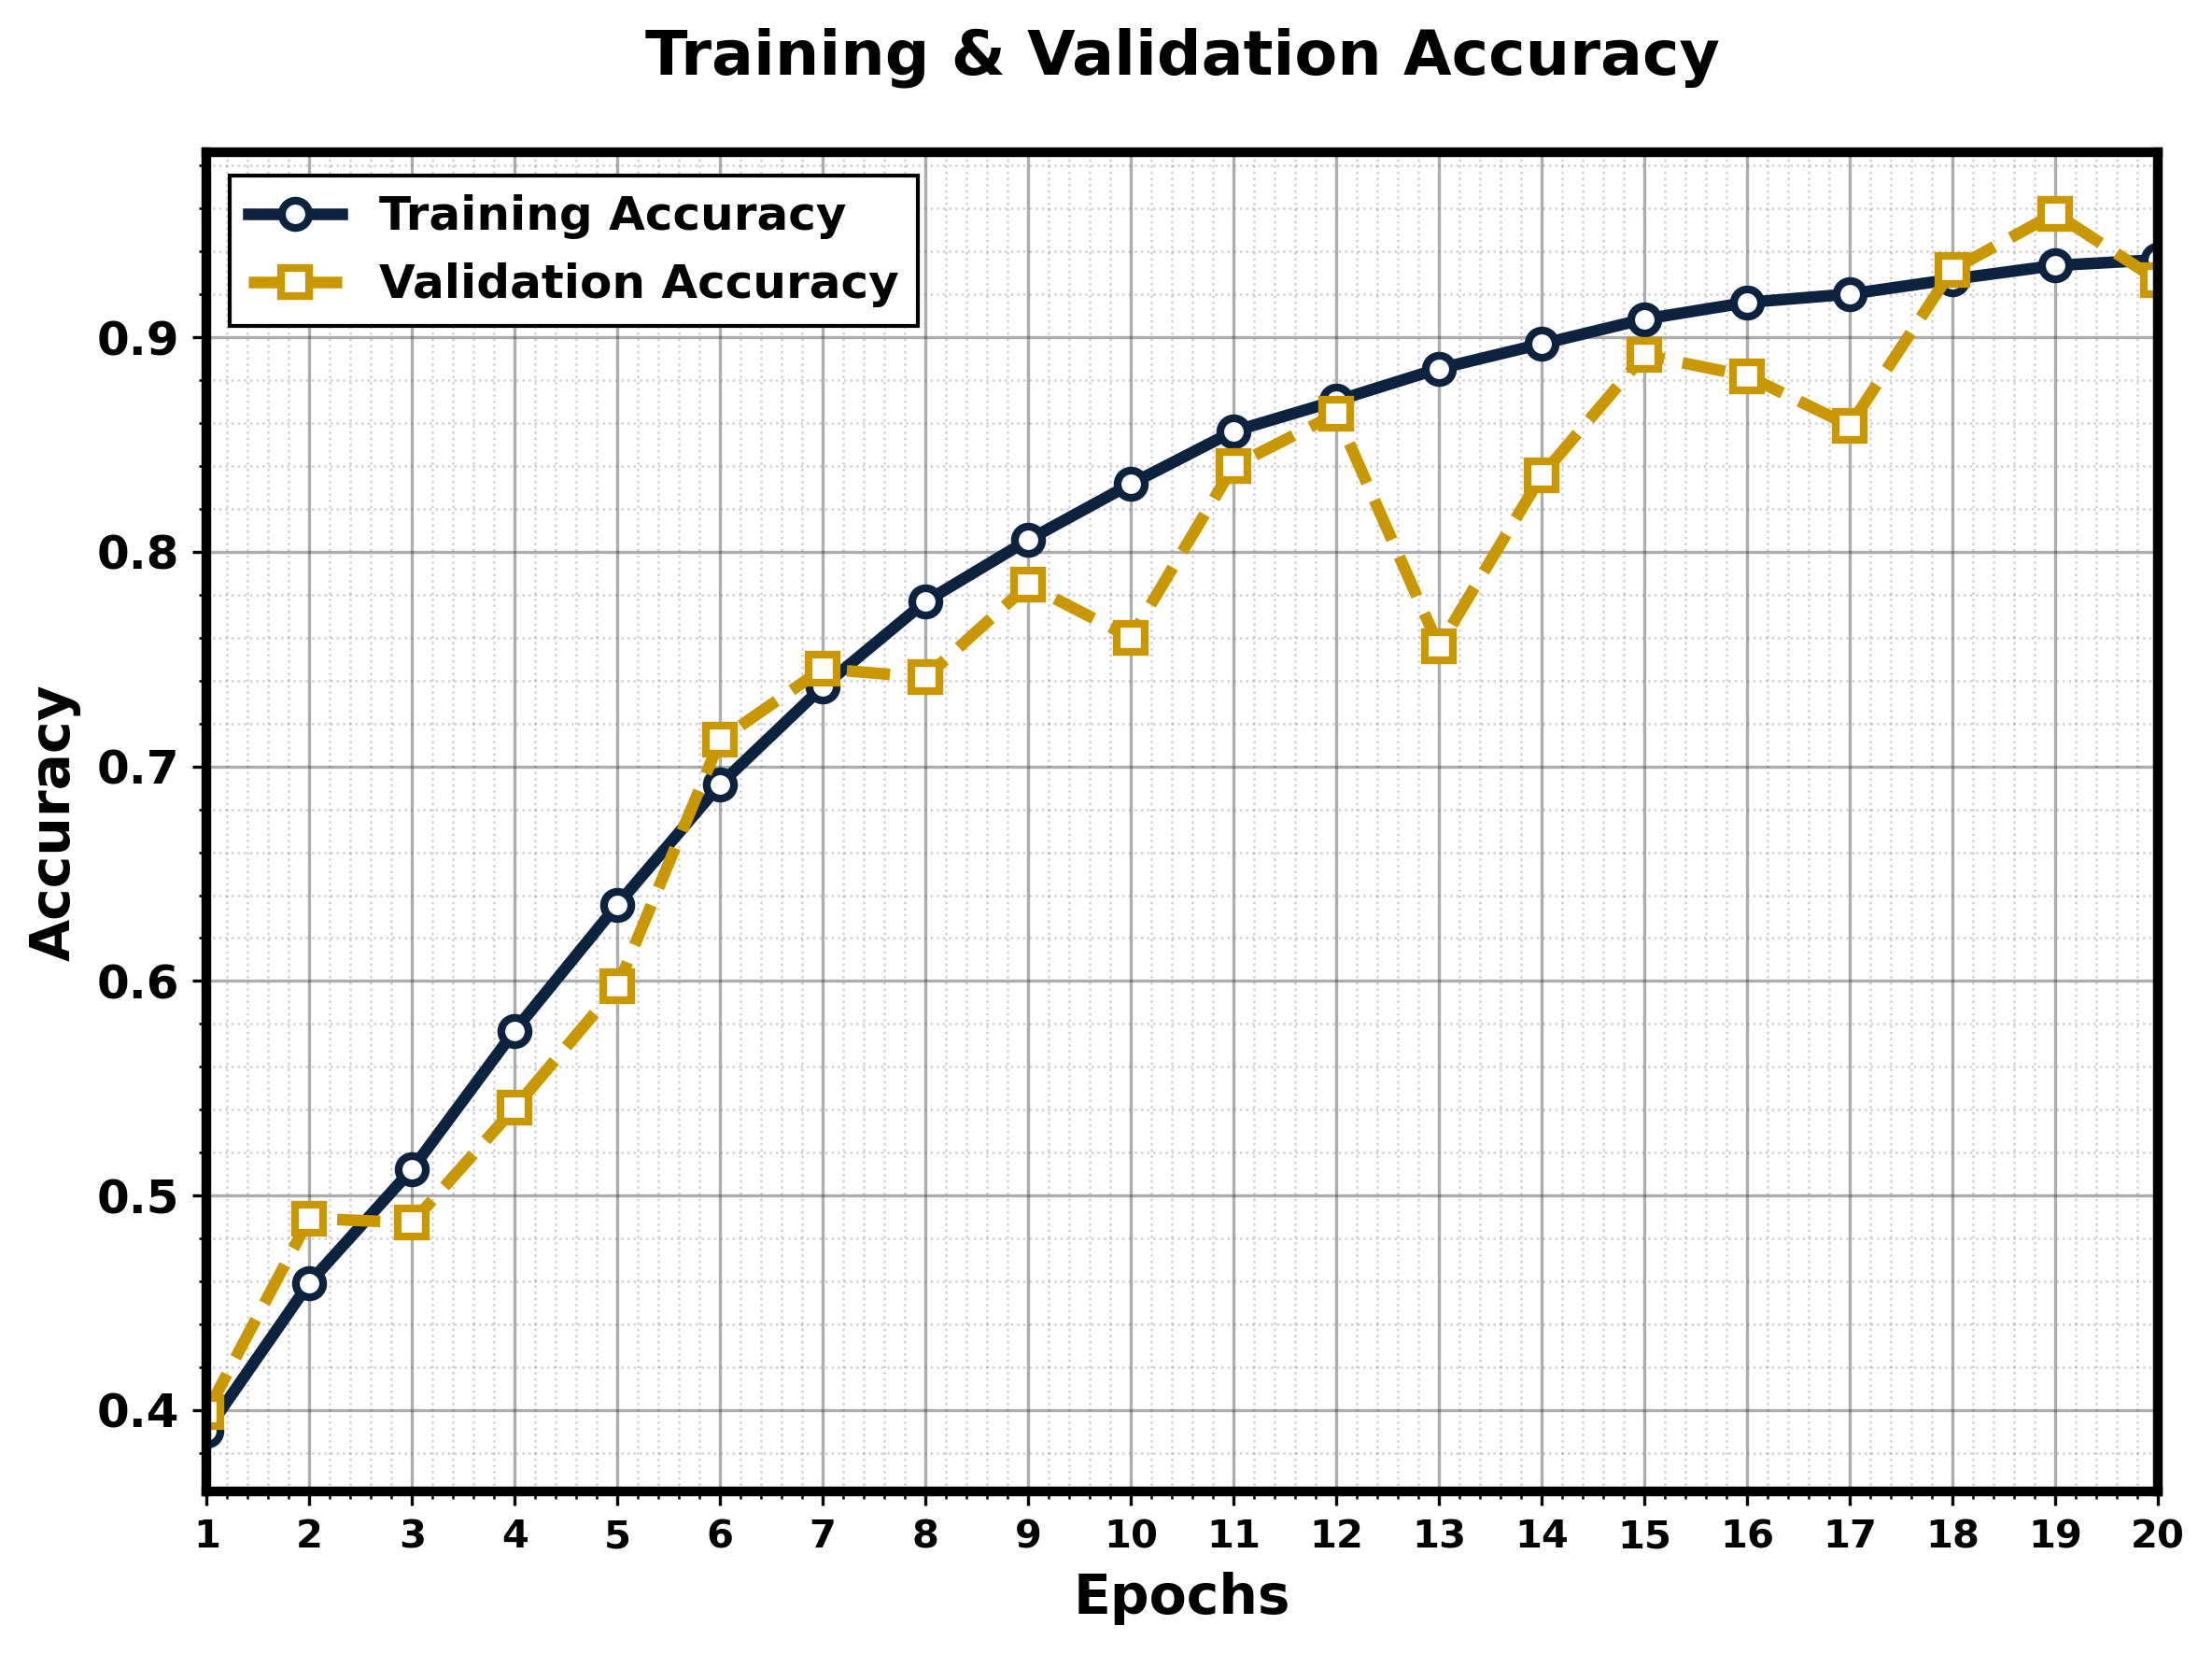

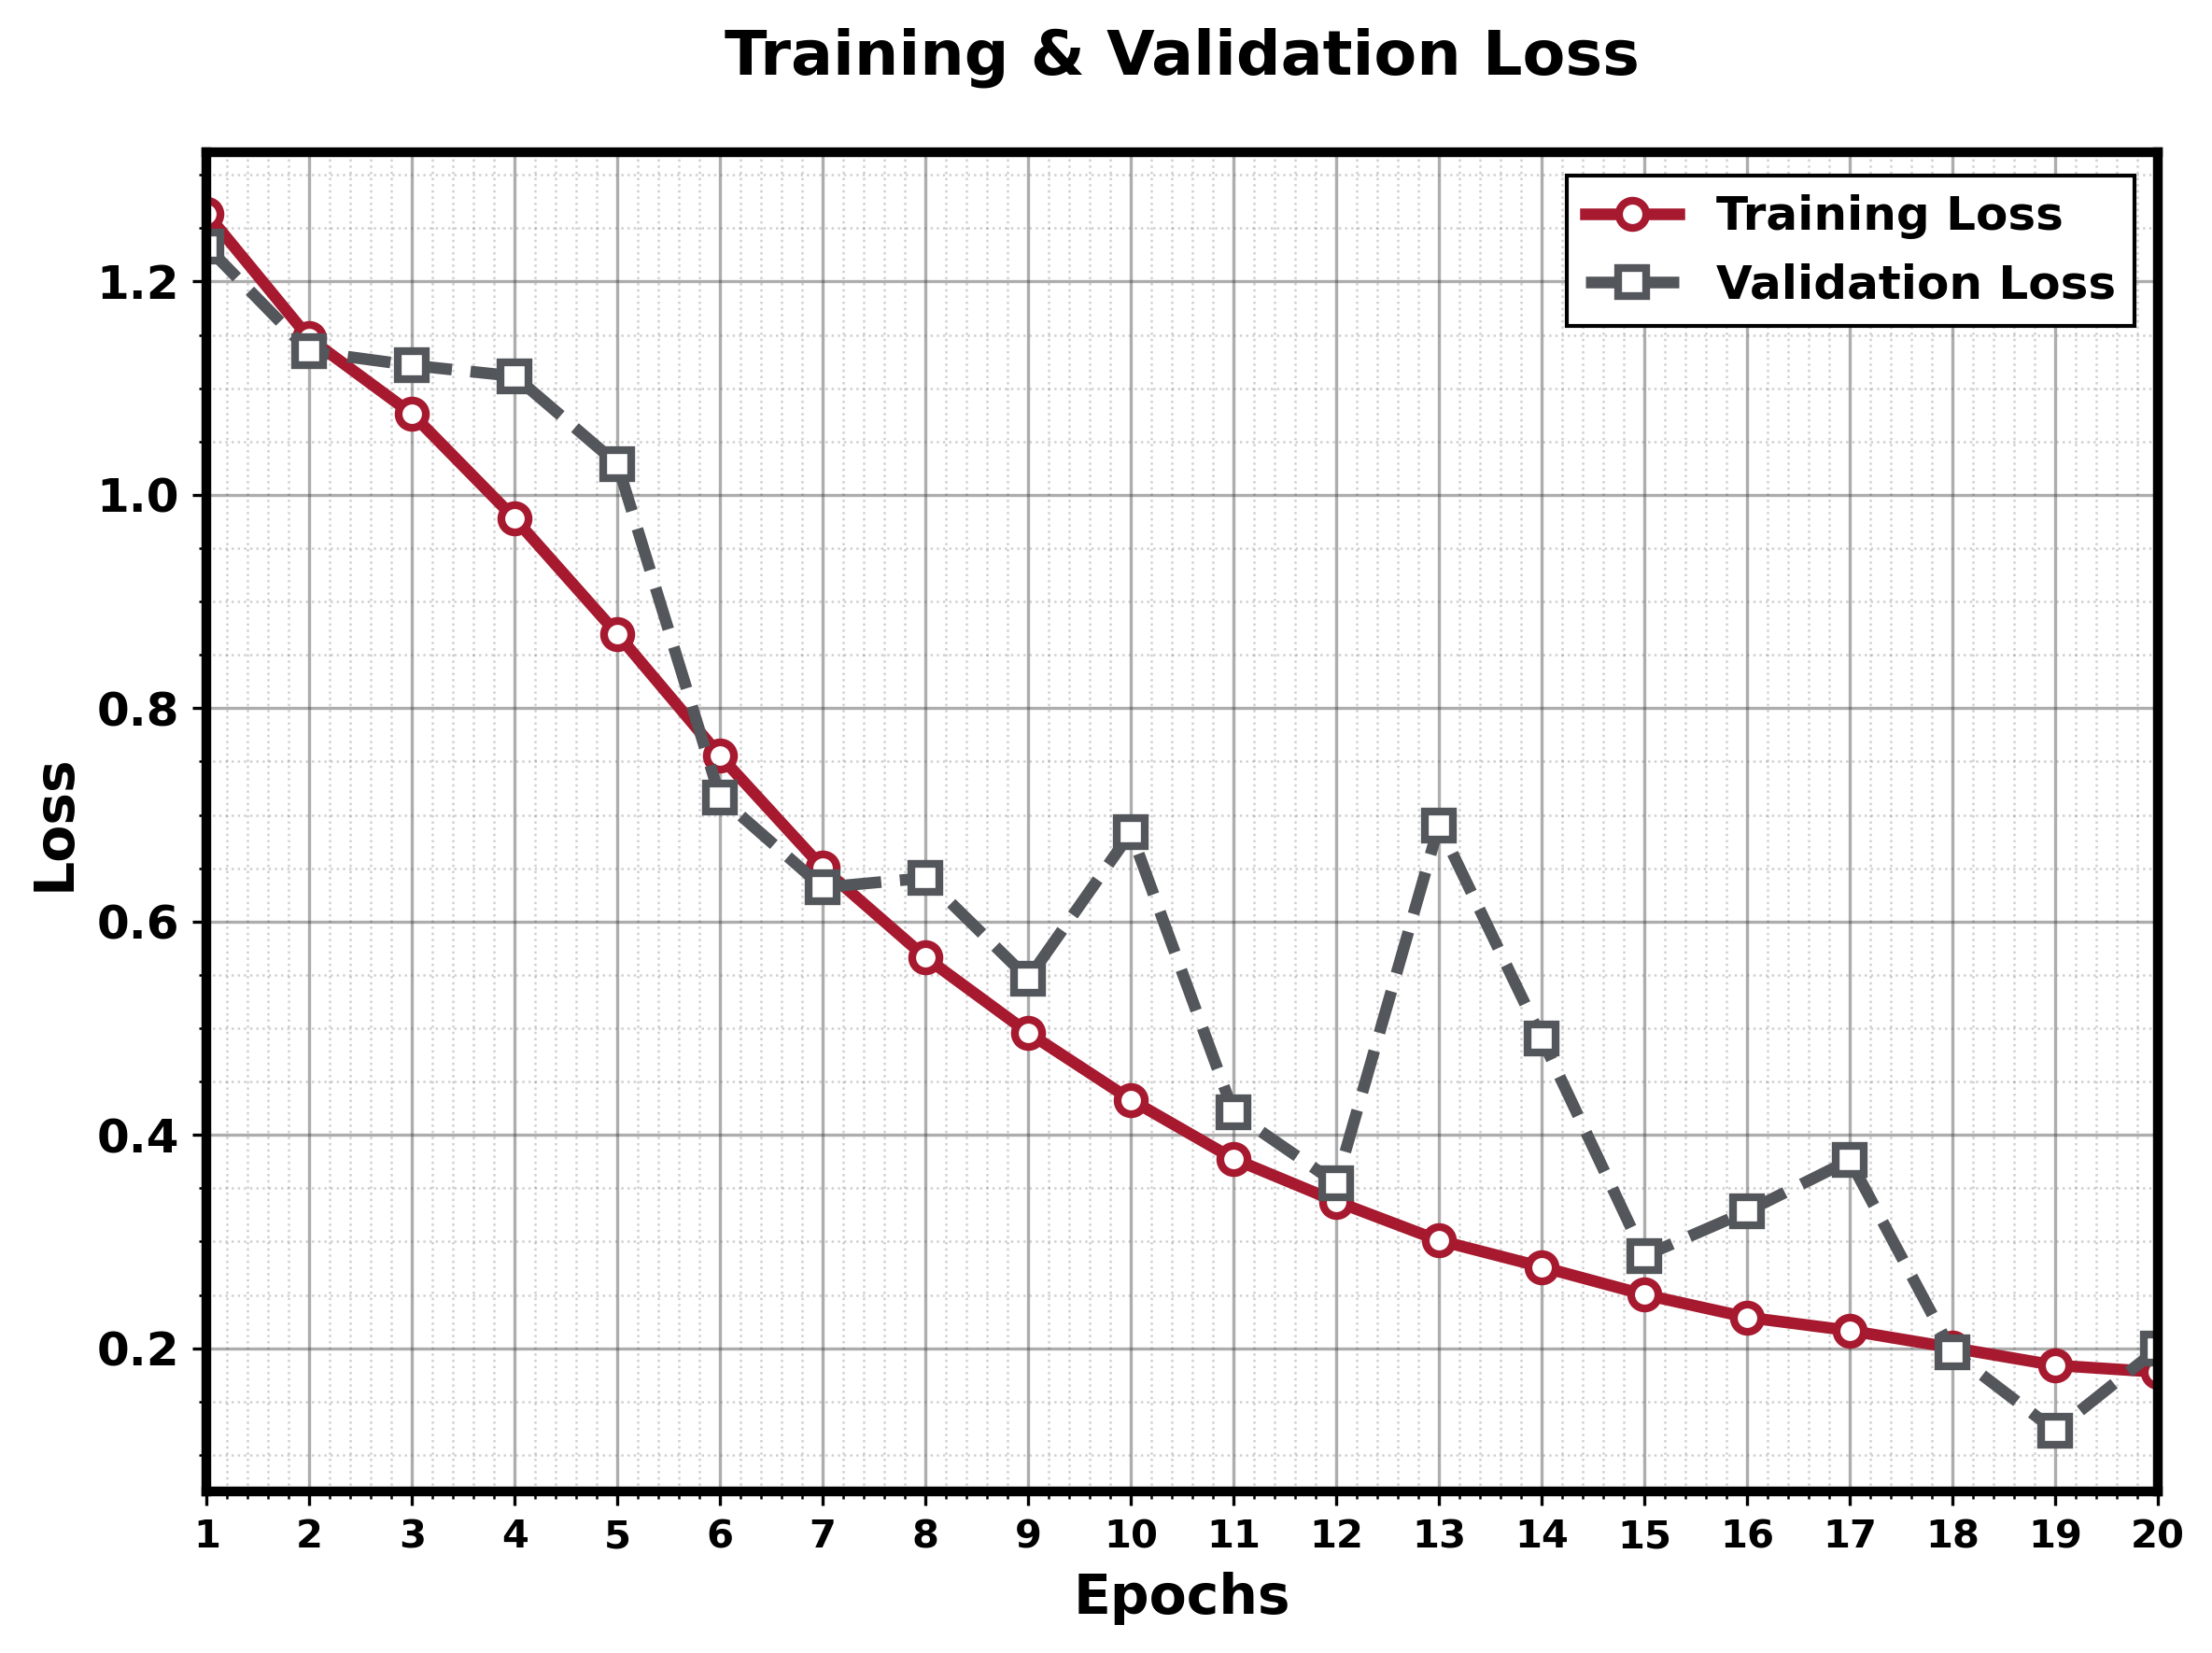

In [8]:
import matplotlib.pyplot as plt
import os
import numpy as np

# Reset to default style
plt.style.use('default')

# Define model name and output directory
model_name = "AlzNetV1"
base_output_dir = "Figures"
output_folder = os.path.join(base_output_dir, model_name)
os.makedirs(output_folder, exist_ok=True)

# Adjusting X-axis data to start from 1
epochs = np.arange(1, 21)
# Ensure history data is truncated or padded to 20 points
train_acc = history.history['accuracy'][:20]
val_acc = history.history['val_accuracy'][:20]
train_loss = history.history['loss'][:20]
val_loss = history.history['val_loss'][:20]

# ==========================================
# PLOT 1: SCIENTIFIC ACCURACY PLOT
# ==========================================
plt.figure(figsize=(8, 6), dpi=300)

plt.plot(epochs, train_acc, label='Training Accuracy', 
         color='#0C2340', linewidth=3, linestyle='-', marker='o', markersize=7, markerfacecolor='white', markeredgewidth=2)
plt.plot(epochs, val_acc, label='Validation Accuracy', 
         color='#C99700', linewidth=3, linestyle='--', marker='s', markersize=7, markerfacecolor='white', markeredgewidth=2)

plt.title('Training & Validation Accuracy', fontsize=16, fontweight='black', pad=20)
plt.xlabel('Epochs', fontsize=14, fontweight='black')
plt.ylabel('Accuracy', fontsize=14, fontweight='black')

# 1. SCIENTIFIC GRID (Dense "Graph Paper" Style)
plt.minorticks_on()
plt.grid(True, which='major', color='#333333', linestyle='-', alpha=0.4, linewidth=0.8)
plt.grid(True, which='minor', color='#666666', linestyle=':', alpha=0.3, linewidth=0.6)

# 2. THE FRAME (Ultra-Bold Bounding Box)
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(2.5)

# 3. TICKS (1 to 20)
plt.xlim(1, 20)
plt.xticks(np.arange(1, 21, 1), fontweight='black', fontsize=10)
plt.yticks(fontweight='black', fontsize=12)

# 4. BOLD LEGEND
plt.legend(prop={'weight': 'black', 'size': 12}, frameon=True, edgecolor='black', framealpha=1, fancybox=False)

plt.tight_layout()
plt.savefig(os.path.join(output_folder, 'accuracy_scientific.png'), dpi=1000, bbox_inches='tight')
plt.show()

# ==========================================
# PLOT 2: SCIENTIFIC LOSS PLOT
# ==========================================
plt.figure(figsize=(8, 6), dpi=300)

plt.plot(epochs, train_loss, label='Training Loss', 
         color='#A6192E', linewidth=3, linestyle='-', marker='o', markersize=7, markerfacecolor='white', markeredgewidth=2)
plt.plot(epochs, val_loss, label='Validation Loss', 
         color='#53565A', linewidth=3, linestyle='--', marker='s', markersize=7, markerfacecolor='white', markeredgewidth=2)

plt.title('Training & Validation Loss', fontsize=16, fontweight='black', pad=20)
plt.xlabel('Epochs', fontsize=14, fontweight='black')
plt.ylabel('Loss', fontsize=14, fontweight='black')

# 1. SCIENTIFIC GRID
plt.minorticks_on()
plt.grid(True, which='major', color='#333333', linestyle='-', alpha=0.4, linewidth=0.8)
plt.grid(True, which='minor', color='#666666', linestyle=':', alpha=0.3, linewidth=0.6)

# 2. THE FRAME
ax2 = plt.gca()
for spine in ax2.spines.values():
    spine.set_edgecolor('black')
    spine.set_linewidth(2.5)

# 3. TICKS (1 to 20)
plt.xlim(1, 20)
plt.xticks(np.arange(1, 21, 1), fontweight='black', fontsize=10)
plt.yticks(fontweight='black', fontsize=12)

# 4. BOLD LEGEND
plt.legend(prop={'weight': 'black', 'size': 12}, frameon=True, edgecolor='black', framealpha=1, fancybox=False)

plt.tight_layout()
plt.savefig(os.path.join(output_folder, 'loss_scientific.png'), dpi=1000, bbox_inches='tight')
plt.show()

✅ Scientific Distribution Plot saved: Figures\AlzNetV1\class_distribution_scientific.png


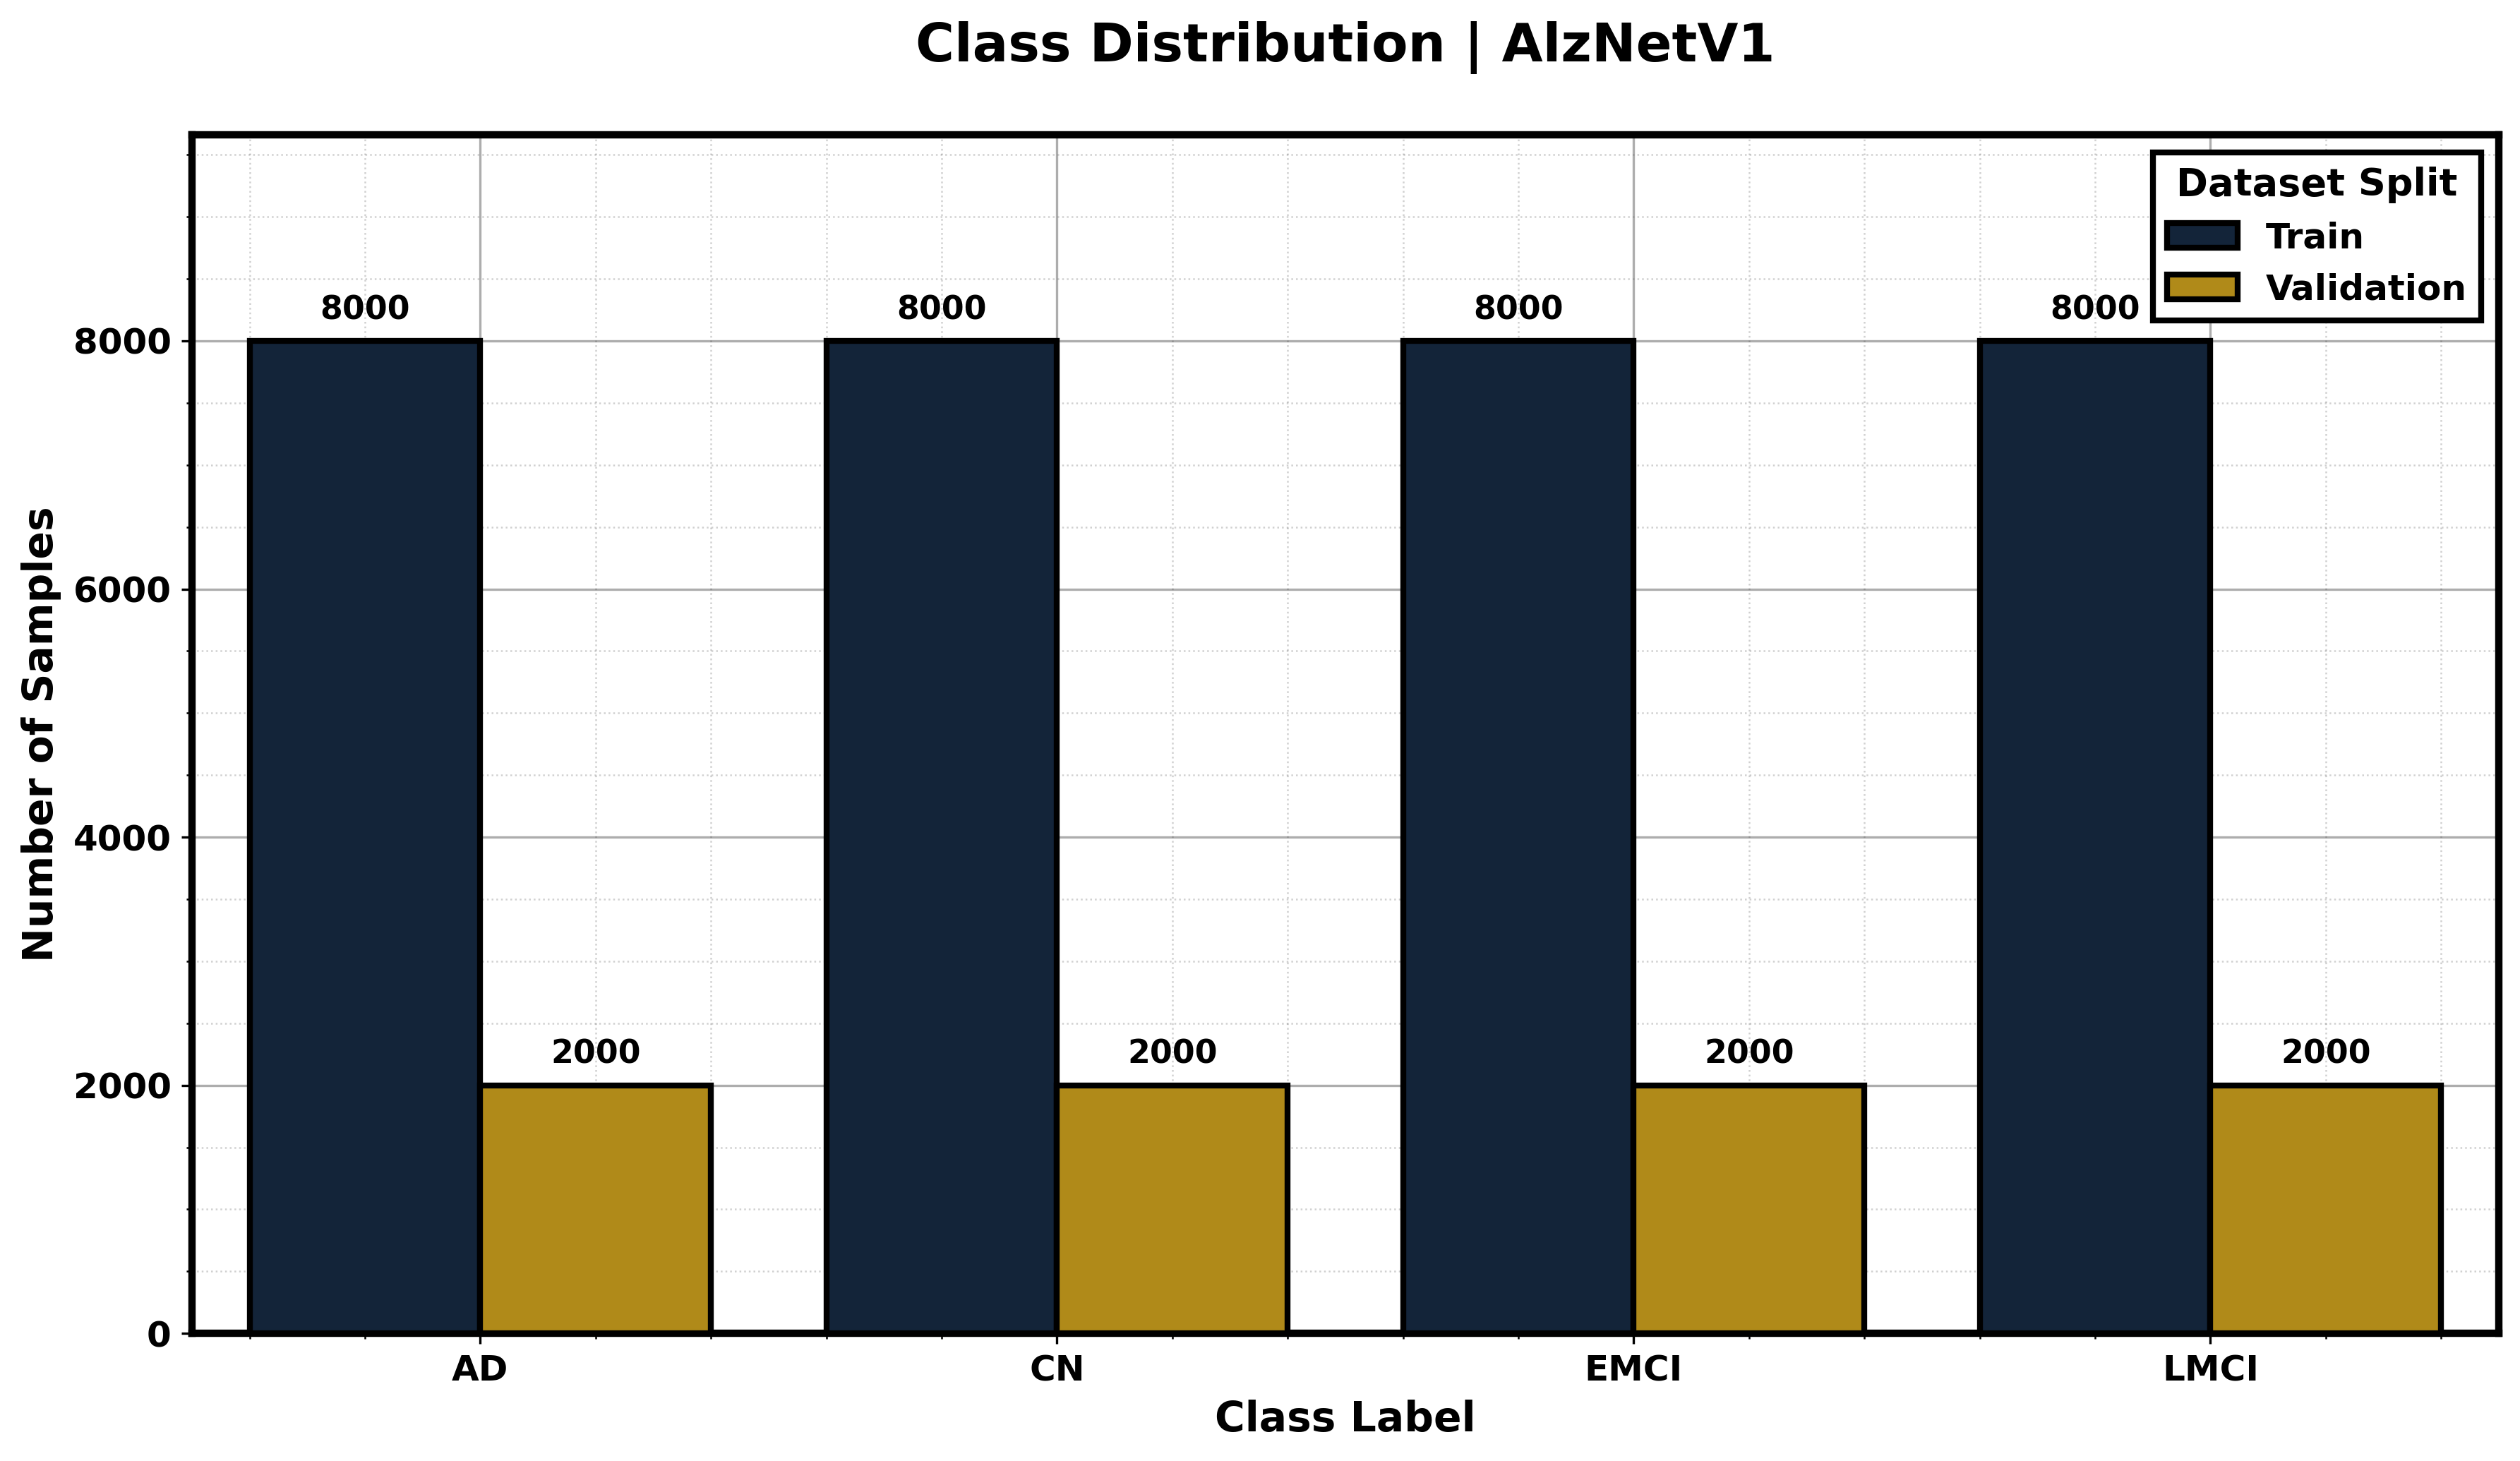

In [9]:
import os
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Reset to default style for full control over scientific elements
plt.style.use('default')

# Define model name and output directory
model_name = "AlzNetV1"
base_output_dir = "Figures"
output_folder = os.path.join(base_output_dir, model_name)
os.makedirs(output_folder, exist_ok=True)

# Map class indices back to class names
class_indices = {v: k for k, v in validation_generator.class_indices.items()}

# Extract validation labels
val_labels = [class_indices[i] for i in validation_generator.classes]
df_val = pd.DataFrame({'Class': val_labels, 'Split': 'Validation'})

# Extract training labels
try:
    train_labels = [class_indices[i] for i in train_generator.classes]
    df_train = pd.DataFrame({'Class': train_labels, 'Split': 'Train'}) 
    df_combined = pd.concat([df_train, df_val], ignore_index=True)
    plot_data = df_combined
    hue_col = 'Split'
    # Using your established professional colors
    palette = ['#0C2340', '#C99700'] 
except NameError:
    plot_data = df_val
    hue_col = 'Class'
    palette = sns.color_palette("tab10", len(df_val['Class'].unique()))

# ---------- SCIENTIFIC GROUPED COUNTPLOT ----------
plt.figure(figsize=(12, 7), dpi=300)

# Create the countplot with black outlines on bars
ax = sns.countplot(
    data=plot_data, 
    x='Class', 
    hue=hue_col, 
    palette=palette, 
    edgecolor='black', 
    linewidth=2.0,
    zorder=3  # Bars above the grid
)

# 1. SCIENTIFIC GRID (Dense "Graph Paper" Style)
plt.minorticks_on()
plt.grid(True, which='major', color='#333333', linestyle='-', alpha=0.4, linewidth=0.8, zorder=0)
plt.grid(True, which='minor', color='#666666', linestyle=':', alpha=0.3, linewidth=0.6, zorder=0)

# 2. THE FRAME (Ultra-Bold 2.5pt Bounding Box)
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_edgecolor('black')
    spine.set_linewidth(2.5)

# 3. LABELS & TICKS (Maximum Boldness/Weight)
plt.title(f'Class Distribution | {model_name}', fontsize=18, fontweight='black', pad=25)
plt.xlabel('Class Label', fontsize=14, fontweight='black')
plt.ylabel('Number of Samples', fontsize=14, fontweight='black')

plt.xticks(rotation=0, fontweight='black', fontsize=12)
plt.yticks(fontweight='black', fontsize=12)

# 4. BAR LABELS (Exact counts on top)
for container in ax.containers:
    ax.bar_label(container, fontweight='black', padding=5, size=11)

# Extra headroom for labels
ax.set_ylim(top=ax.get_ylim()[1] * 1.15)

# 5. ULTRA-BOLD LEGEND (Matched Box)
if hue_col == 'Split':
    leg = plt.legend(
        title='Dataset Split', 
        prop={'weight': 'black', 'size': 12}, 
        frameon=True, 
        edgecolor='black', 
        framealpha=1.0, 
        fancybox=False,
        loc='upper right'
    )
    plt.setp(leg.get_title(), weight='black', size=13)
    leg.get_frame().set_linewidth(2.0)
else:
    if ax.get_legend(): ax.get_legend().remove()

plt.tight_layout()

# Save at high-quality publication resolution
plot_path = os.path.join(output_folder, 'class_distribution_scientific.png')
plt.savefig(plot_path, dpi=1000, bbox_inches='tight')

print(f"✅ Scientific Distribution Plot saved: {plot_path}")
plt.show()

In [10]:
import numpy as np
import os
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# ==========================================
# PREDICTIONS & EVALUATION
# ==========================================

# Get true labels and class names
val_labels = validation_generator.classes
class_names = list(validation_generator.class_indices.keys())

# Predict classes
# Note: Ensure shuffle=False in your validation_generator for labels to match predictions
val_predictions = model.predict(
    validation_generator, 
    steps=len(validation_generator)
)
val_pred_classes = np.argmax(val_predictions, axis=1)

# Generate Classification Report with 5 decimal points
report = classification_report(
    val_labels, 
    val_pred_classes, 
    target_names=class_names, 
    digits=5
)

print(f"--- Classification Report for {model_name} ---")
print(report)

# ==========================================
# OPTIONAL: SAVE REPORT TO TEXT FILE
# ==========================================
report_path = os.path.join(output_folder, "classification_report.txt")
with open(report_path, "w") as f:
    f.write(f"Model: {model_name}\n")
    f.write(report)

print(f"Detailed report saved to: {report_path}")

500/500 [==============================] - 106s 211ms/step
--- Classification Report for AlzNetV1 ---
              precision    recall  f1-score   support

          AD    0.92450   0.92450   0.92450      2000
          CN    0.95624   0.87400   0.91327      2000
        EMCI    0.97851   0.93350   0.95548      2000
        LMCI    0.87942   0.99550   0.93386      2000

    accuracy                        0.93188      8000
   macro avg    0.93467   0.93188   0.93178      8000
weighted avg    0.93467   0.93188   0.93178      8000

Detailed report saved to: Figures\AlzNetV1\classification_report.txt


In [11]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
from mpl_toolkits.axes_grid1 import make_axes_locatable

# ==========================================
# 1. SETUP & DATA PREPARATION
# ==========================================
model_name = "AlzNetV1"
base_output_dir = "Figures"
output_folder = os.path.join(base_output_dir, model_name)
os.makedirs(output_folder, exist_ok=True)

# Generate Confusion Matrix
cm = confusion_matrix(val_labels, val_pred_classes)
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# Labels (Count + Percentage)
group_counts = ["{0:0.0f}".format(v) for v in cm.flatten()]
group_percent = ["{0:.2%}".format(v) for v in cm_percent.flatten()]
labels = [f"{c}\n({p})" for c, p in zip(group_counts, group_percent)]
labels = np.asarray(labels).reshape(cm.shape)

# ==========================================
# 2. JOURNAL-READY PLOTTING (MATCHED HEIGHT)
# ==========================================
fig, ax = plt.subplots(figsize=(12, 8), dpi=1000)
plt.style.use('default')

# Create a divider for the existing axes to match colorbar height exactly
divider = make_axes_locatable(ax)
cax = divider.append_axes("right", size="5%", pad=0.15)

# Heatmap Configuration
sns.heatmap(
    cm,
    annot=labels,
    fmt="",
    cmap="Greens",
    linewidths=1.5,
    linecolor="black",
    square=True,
    xticklabels=validation_generator.class_indices.keys(),
    yticklabels=validation_generator.class_indices.keys(),
    ax=ax,
    cbar_ax=cax,  # Forces colorbar into the matched-height axis
    annot_kws={"fontsize": 10, "fontweight": "bold", "family": "serif"}
)

# --- COLORBAR STYLING ---
cbar = ax.collections[0].colorbar
cbar.outline.set_edgecolor('black')
cbar.outline.set_linewidth(1.5)

for label in cbar.ax.get_yticklabels():
    label.set_fontweight('bold')
    label.set_family('serif')
    label.set_fontsize(10)

# --- TITLES & LABELS (SERIF + BOLD) ---
ax.set_title(f'{model_name} Performance Analysis', 
             fontsize=18, fontweight='bold', pad=25, family='serif')

ax.set_xlabel("Predicted Category", fontsize=14, fontweight='bold', labelpad=12, family='serif')
ax.set_ylabel("True Category", fontsize=14, fontweight='bold', labelpad=12, family='serif')

# --- TICK STYLING ---
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontweight="bold", family='serif')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontweight="bold", family='serif')

# --- HEAVY FRAME (Signature 2.5pt) ---
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_edgecolor('black')
    spine.set_linewidth(2.5)

# Also frame the colorbar axis
for spine in cax.spines.values():
    spine.set_visible(True)
    spine.set_edgecolor('black')
    spine.set_linewidth(1.5)

# ==========================================
# 3. EXPORT
# ==========================================
plt.tight_layout()

plot_path = os.path.join(output_folder, "confusion_matrix_matched_height.png")
plt.savefig(plot_path, dpi=1000, bbox_inches="tight", pad_inches=0.1)
plt.show()

print(f"[SUCCESS] Matrix with matched height colorbar saved to: {plot_path}")

[SUCCESS] Matrix with matched height colorbar saved to: Figures\AlzNetV1\confusion_matrix_matched_height.png


In [12]:
# Get training and validation metrics from the history object
train_loss = history.history['loss'][-1]
train_acc = history.history['accuracy'][-1]
val_loss = history.history['val_loss'][-1]
val_acc = history.history['val_accuracy'][-1]

print(f'Training loss: {train_loss}')
print(f'Training accuracy: {train_acc}')
print(f'Validation loss: {val_loss}')
print(f'Validation accuracy: {val_acc}')

Training loss: 0.17779164016246796
Training accuracy: 0.9361562728881836
Validation loss: 0.19959695637226105
Validation accuracy: 0.9265000224113464


In [13]:
import os
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, matthews_corrcoef, precision_score, recall_score, f1_score

# ==========================================
# 1. GENERATE PREDICTIONS
# ==========================================
validation_generator.reset()  # Reset to ensure order matches
Y_pred = model.predict(validation_generator, steps=len(validation_generator))
y_pred = np.argmax(Y_pred, axis=1)
y_true = validation_generator.classes
target_names = list(validation_generator.class_indices.keys())

# ==========================================
# 2. CALCULATE METRICS (5 Decimal Points)
# ==========================================
# Classification Report
report = classification_report(y_true, y_pred, target_names=target_names, digits=5)

# Macro Metrics
precision = precision_score(y_true, y_pred, average='macro')
recall = recall_score(y_true, y_pred, average='macro')
f1 = f1_score(y_true, y_pred, average='macro')
mcc = matthews_corrcoef(y_true, y_pred)

# Confusion Matrix based Sensitivity/Specificity
cm = confusion_matrix(y_true, y_pred)
TP = np.diag(cm)
FP = cm.sum(axis=0) - TP
FN = cm.sum(axis=1) - TP
TN = cm.sum() - (FP + FN + TP)

sensitivity = TP / (TP + FN)
specificity = TN / (TN + FP)

# ==========================================
# 3. PRINT FORMATTED OUTPUT
# ==========================================
print(f"\n{'='*60}")
print(f"ULTRA-PRO EVALUATION REPORT: {model_name}")
print(f"{'='*60}\n")

print("CLASSIFICATION REPORT:")
print(report)

print("-" * 30)
print(f"{'Metric':<20} | {'Value':<10}")
print("-" * 30)
print(f"{'Macro Precision':<20} | {precision:.5f}")
print(f"{'Macro Recall':<20} | {recall:.5f}")
print(f"{'Macro F1-Score':<20} | {f1:.5f}")
print(f"{'MCC':<20} | {mcc:.5f}")
print("-" * 30)

print("\nPER-CLASS METRICS:")
for i, name in enumerate(target_names):
    print(f"Class: {name}")
    print(f"  - Sensitivity (Recall): {sensitivity[i]:.5f}")
    print(f"  - Specificity:          {specificity[i]:.5f}")

# ==========================================
# 4. SAVE TO FILE
# ==========================================
results_path = os.path.join(output_folder, "model_evaluation_metrics.txt")
with open(results_path, "w") as f:
    f.write(f"EVALUATION REPORT: {model_name}\n")
    f.write("="*40 + "\n")
    f.write(report + "\n")
    f.write(f"Macro Precision: {precision:.5f}\n")
    f.write(f"Macro Recall:    {recall:.5f}\n")
    f.write(f"Macro F1-Score:  {f1:.5f}\n")
    f.write(f"MCC:             {mcc:.5f}\n\n")
    f.write("PER-CLASS METRICS\n")
    for i, name in enumerate(target_names):
        f.write(f"{name}: Sens={sensitivity[i]:.5f}, Spec={specificity[i]:.5f}\n")

print(f"\n[INFO] All metrics saved to: {results_path}")

500/500 [==============================] - 105s 211ms/step

ULTRA-PRO EVALUATION REPORT: AlzNetV1

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

          AD    0.92350   0.91750   0.92049      2000
          CN    0.95197   0.87200   0.91023      2000
        EMCI    0.97147   0.91950   0.94477      2000
        LMCI    0.86888   0.99400   0.92724      2000

    accuracy                        0.92575      8000
   macro avg    0.92896   0.92575   0.92568      8000
weighted avg    0.92896   0.92575   0.92568      8000

------------------------------
Metric               | Value     
------------------------------
Macro Precision      | 0.92896
Macro Recall         | 0.92575
Macro F1-Score       | 0.92568
MCC                  | 0.90215
------------------------------

PER-CLASS METRICS:
Class: AD
  - Sensitivity (Recall): 0.91750
  - Specificity:          0.97467
Class: CN
  - Sensitivity (Recall): 0.87200
  - Specificity:          0.98533
Class: EMCI
  - 

500/500 [==============================] - 106s 211ms/step


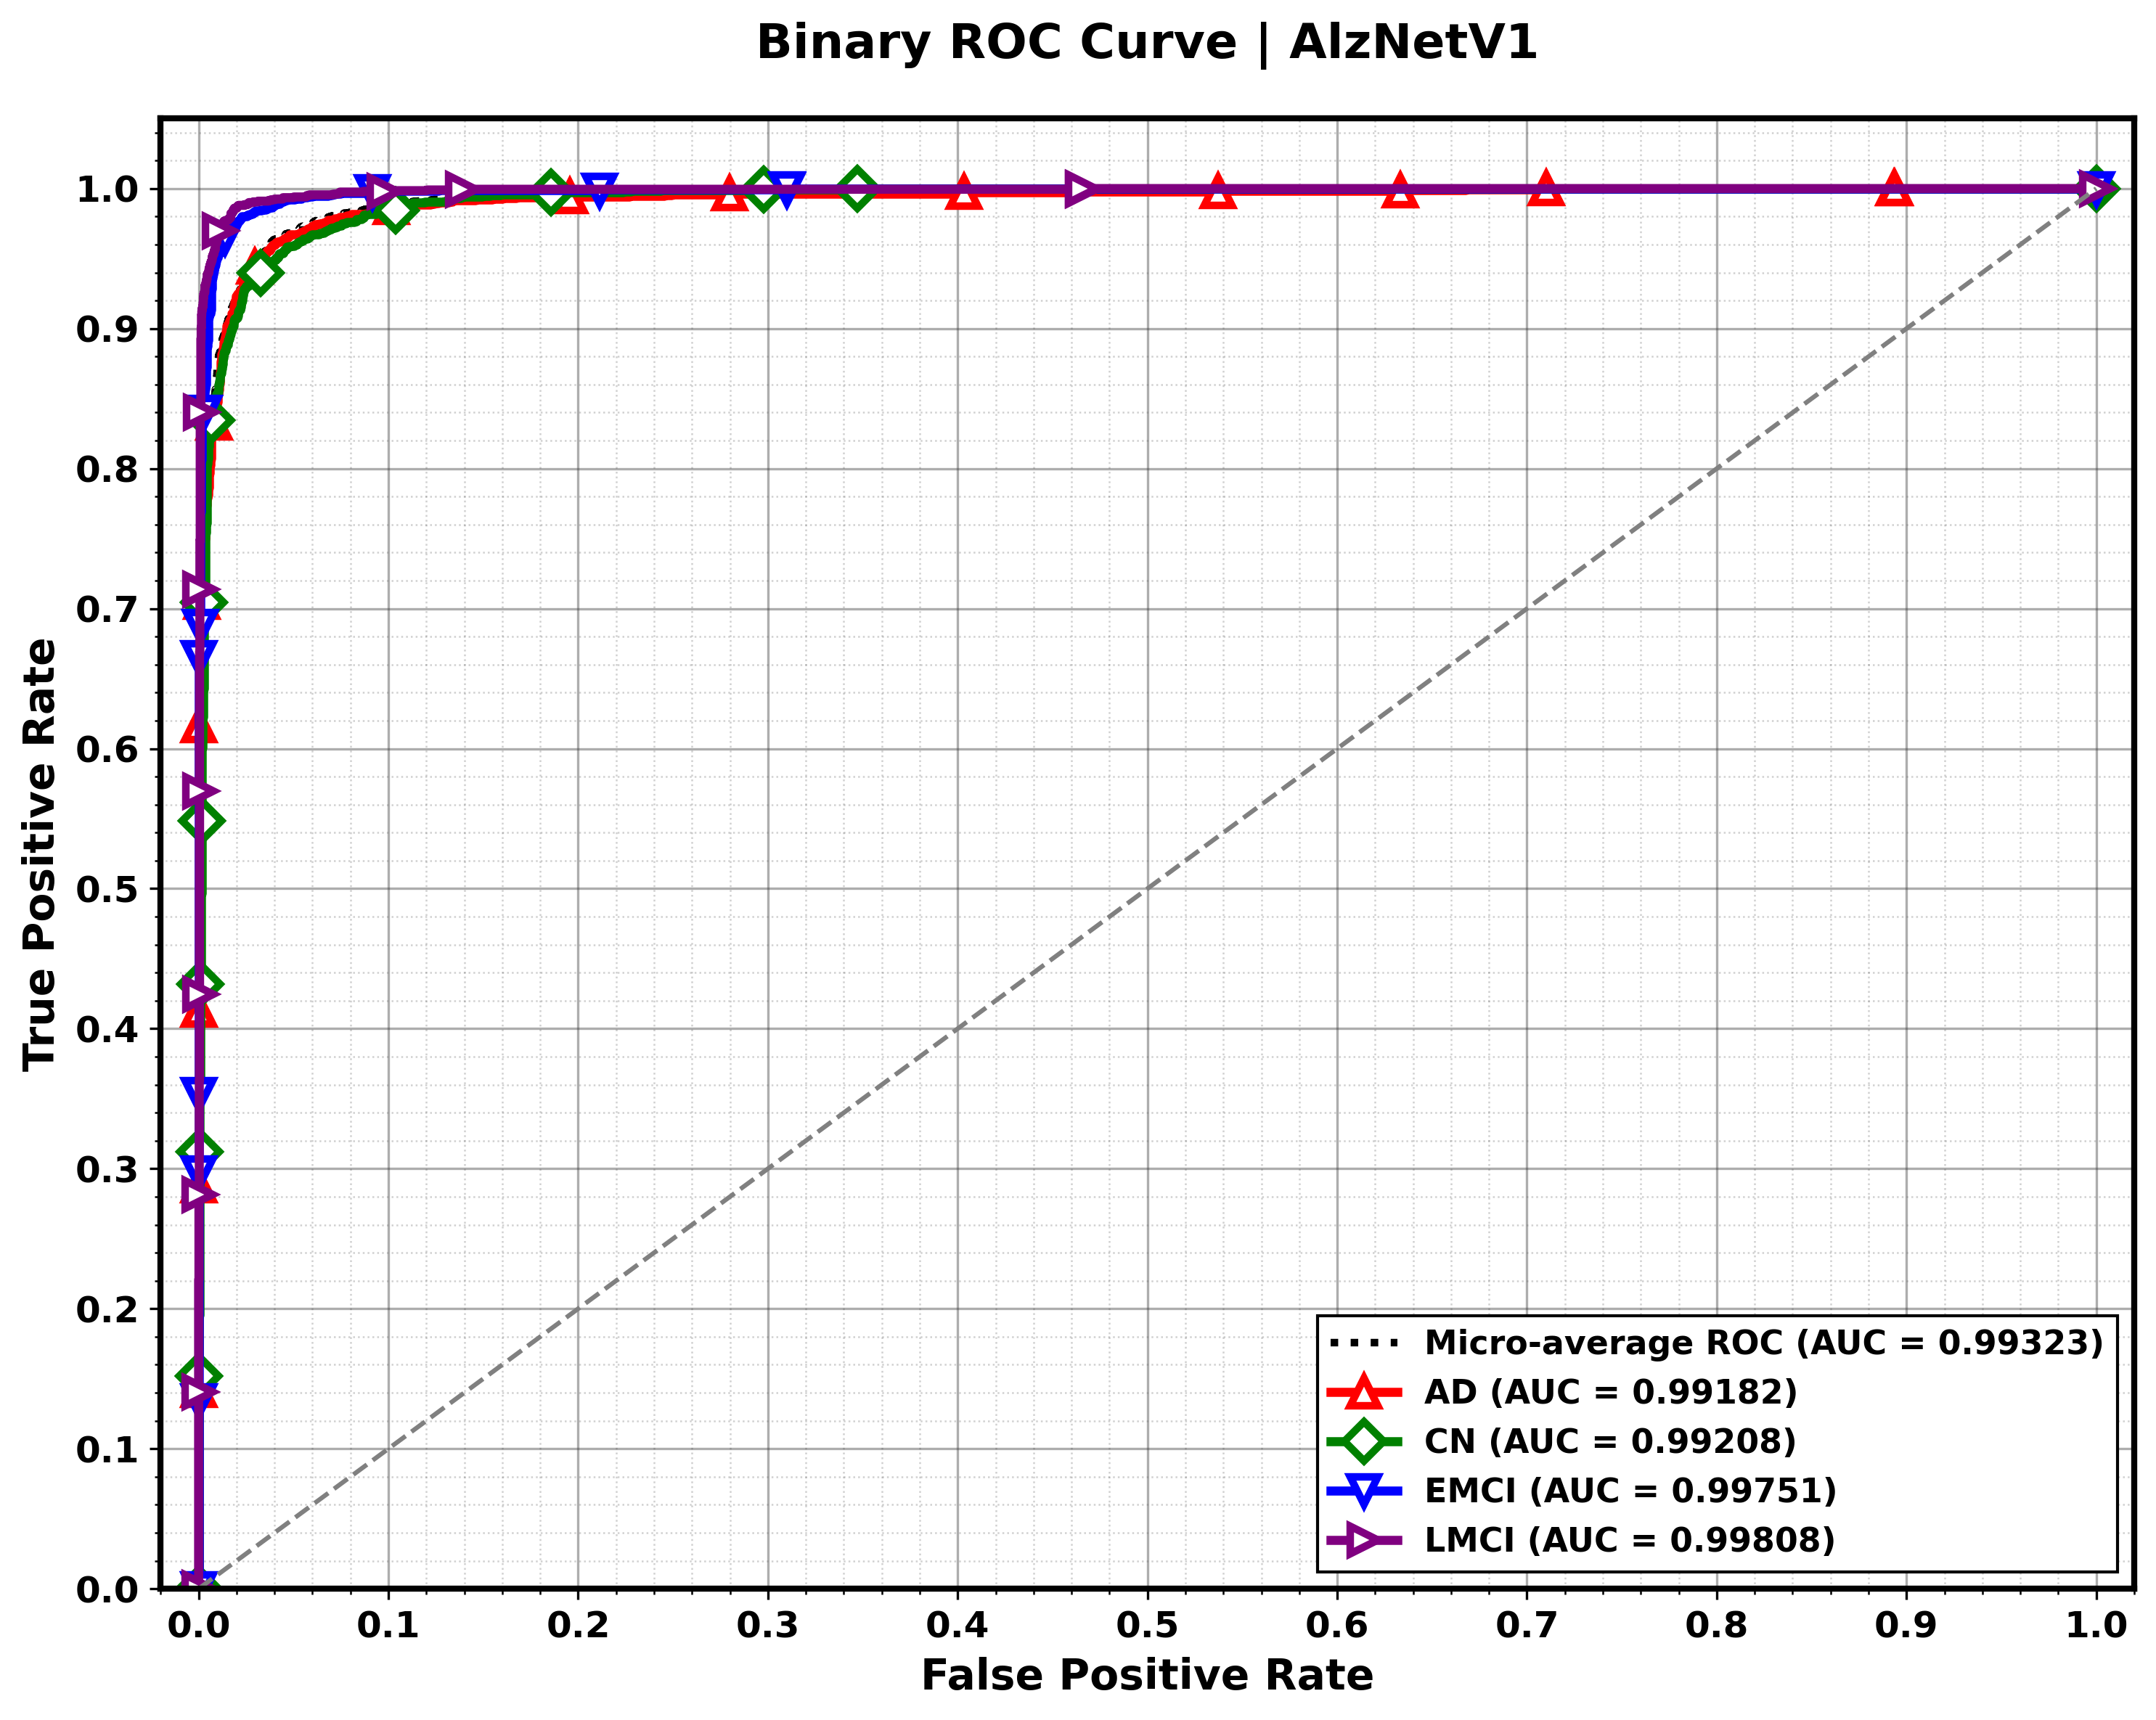

Final scientific ROC curve saved to: Figures\AlzNetV1\roc_curve_final_academic.png


In [14]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# ==========================================
# 1. SETUP & DATA PREPARATION
# ==========================================
model_name = "AlzNetV1"
base_output_dir = "Figures"
output_folder = os.path.join(base_output_dir, model_name)
os.makedirs(output_folder, exist_ok=True)

# Reset generator and get predictions
validation_generator.reset()
y_pred_prob = model.predict(validation_generator, steps=len(validation_generator))

# Binarize labels for multi-class support
class_indices = validation_generator.class_indices
class_names = list(class_indices.keys())
n_classes = len(class_names)
y_true_bin = label_binarize(validation_generator.classes, classes=np.arange(n_classes))

# ==========================================
# -> FIX FOR TWO CLASSES (BINARY)
# ==========================================
if n_classes == 2:
    # label_binarize outputs (N, 1) for binary, we force it to (N, 2) for the loop
    y_true_bin = np.hstack((1 - y_true_bin, y_true_bin))
    
    # If the model outputs a single probability column (N, 1) via sigmoid
    if y_pred_prob.shape[1] == 1:
        y_pred_prob = np.hstack((1 - y_pred_prob, y_pred_prob))

# ==========================================
# 2. COMPUTE ROC & AUC
# ==========================================
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute micro-average ROC curve and AUC (The "Pro" Touch)
fpr["micro"], tpr["micro"], _ = roc_curve(y_true_bin.ravel(), y_pred_prob.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# ==========================================
# 3. SCIENTIFIC PLOTTING (Final Academic Version)
# ==========================================
plt.figure(figsize=(10, 8), dpi=300)
plt.style.use('default') 

# 1. COLOR & MARKER PALETTE (Requested: Blue, Green, Red, Yellow, Pink)
custom_colors = ['red', 'green', 'blue', 'purple', 'magenta']
custom_markers = ['^', 'D', 'v', '>', '*'] # Matching shapes from reference

# Plot Micro-average (Top-level aggregation)
plt.plot(fpr["micro"], tpr["micro"],
         label=f'Micro-average ROC (AUC = {roc_auc["micro"]:.5f})',
         color='black', linestyle=':', linewidth=2.5)

# Plot each class using the requested palette
for i in range(n_classes):
    color = custom_colors[i % len(custom_colors)]
    marker = custom_markers[i % len(custom_markers)]
    
    plt.plot(fpr[i], tpr[i], 
             color=color, 
             marker=marker, 
             markevery=0.08,     # Visual spacing like the reference image
             markersize=9, 
             markerfacecolor='white', # High-contrast markers
             markeredgewidth=2.5,
             lw=3,
             label=f'{class_names[i]} (AUC = {roc_auc[i]:.5f})')

# Random Guess Line
plt.plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--')

# --- STYLING TO MATCH REFERENCE BACKGROUND ---

# 2. THE SCIENTIFIC GRID (Dense "Graph Paper" Style)
plt.minorticks_on()
# Major grid: Darker and solid
plt.grid(True, which='major', color='#333333', linestyle='-', alpha=0.4, linewidth=0.8)
# Minor grid: Lighter and dotted (creates the tiny squares)
plt.grid(True, which='minor', color='#666666', linestyle=':', alpha=0.3, linewidth=0.6)

# 3. AXIS LIMITS & TICKS (Precise 0.1 intervals)
plt.xlim([-0.02, 1.02])
plt.ylim([0.0, 1.05])
plt.xticks(np.arange(0, 1.1, 0.1), fontweight='bold', fontsize=12)
plt.yticks(np.arange(0, 1.1, 0.1), fontweight='bold', fontsize=12)

# 4. THE FRAME (Bold black bounding box)
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('black')
    spine.set_linewidth(2.0)

# 5. LEGEND (Sharp square box with black border)
plt.legend(loc="lower right", prop={'weight': 'bold', 'size': 11}, 
           frameon=True, edgecolor='black', framealpha=1, fancybox=False)

plt.title(f'Binary ROC Curve | {model_name}', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('False Positive Rate', fontsize=14, fontweight='bold')
plt.ylabel('True Positive Rate', fontsize=14, fontweight='bold')

plt.tight_layout()

# Save Plot
roc_path = os.path.join(output_folder, "roc_curve_final_academic.png")
plt.savefig(roc_path, dpi=1000, bbox_inches='tight')
plt.show()

print(f"Final scientific ROC curve saved to: {roc_path}")

In [15]:
# Get true labels and predicted labels for validation set
validation_generator.reset()  # Reset before predicting
Y_pred = model.predict(validation_generator, steps=validation_generator.samples // validation_generator.batch_size + 1)
y_pred = np.argmax(Y_pred, axis=1)

# True labels
y_true = validation_generator.classes

# Classification Report
target_names = list(validation_generator.class_indices.keys())
print("Classification Report:")
print(classification_report(y_true, y_pred, target_names=target_names))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
print("Confusion Matrix:")
print(cm)

501/501 [==============================] - 108s 215ms/step
Classification Report:
              precision    recall  f1-score   support

          AD       0.93      0.92      0.93      2000
          CN       0.95      0.88      0.91      2000
        EMCI       0.97      0.92      0.94      2000
        LMCI       0.88      1.00      0.93      2000

    accuracy                           0.93      8000
   macro avg       0.93      0.93      0.93      8000
weighted avg       0.93      0.93      0.93      8000

Confusion Matrix:
[[1847   42   24   87]
 [ 126 1754   30   90]
 [  10   42 1845  103]
 [   1    1    6 1992]]


In [16]:
from sklearn.metrics import cohen_kappa_score
kappa = cohen_kappa_score(y_true, y_pred)
print(f"Cohen's Kappa: {kappa}")


Cohen's Kappa: 0.9063333333333333


500/500 [==============================] - 106s 211ms/step


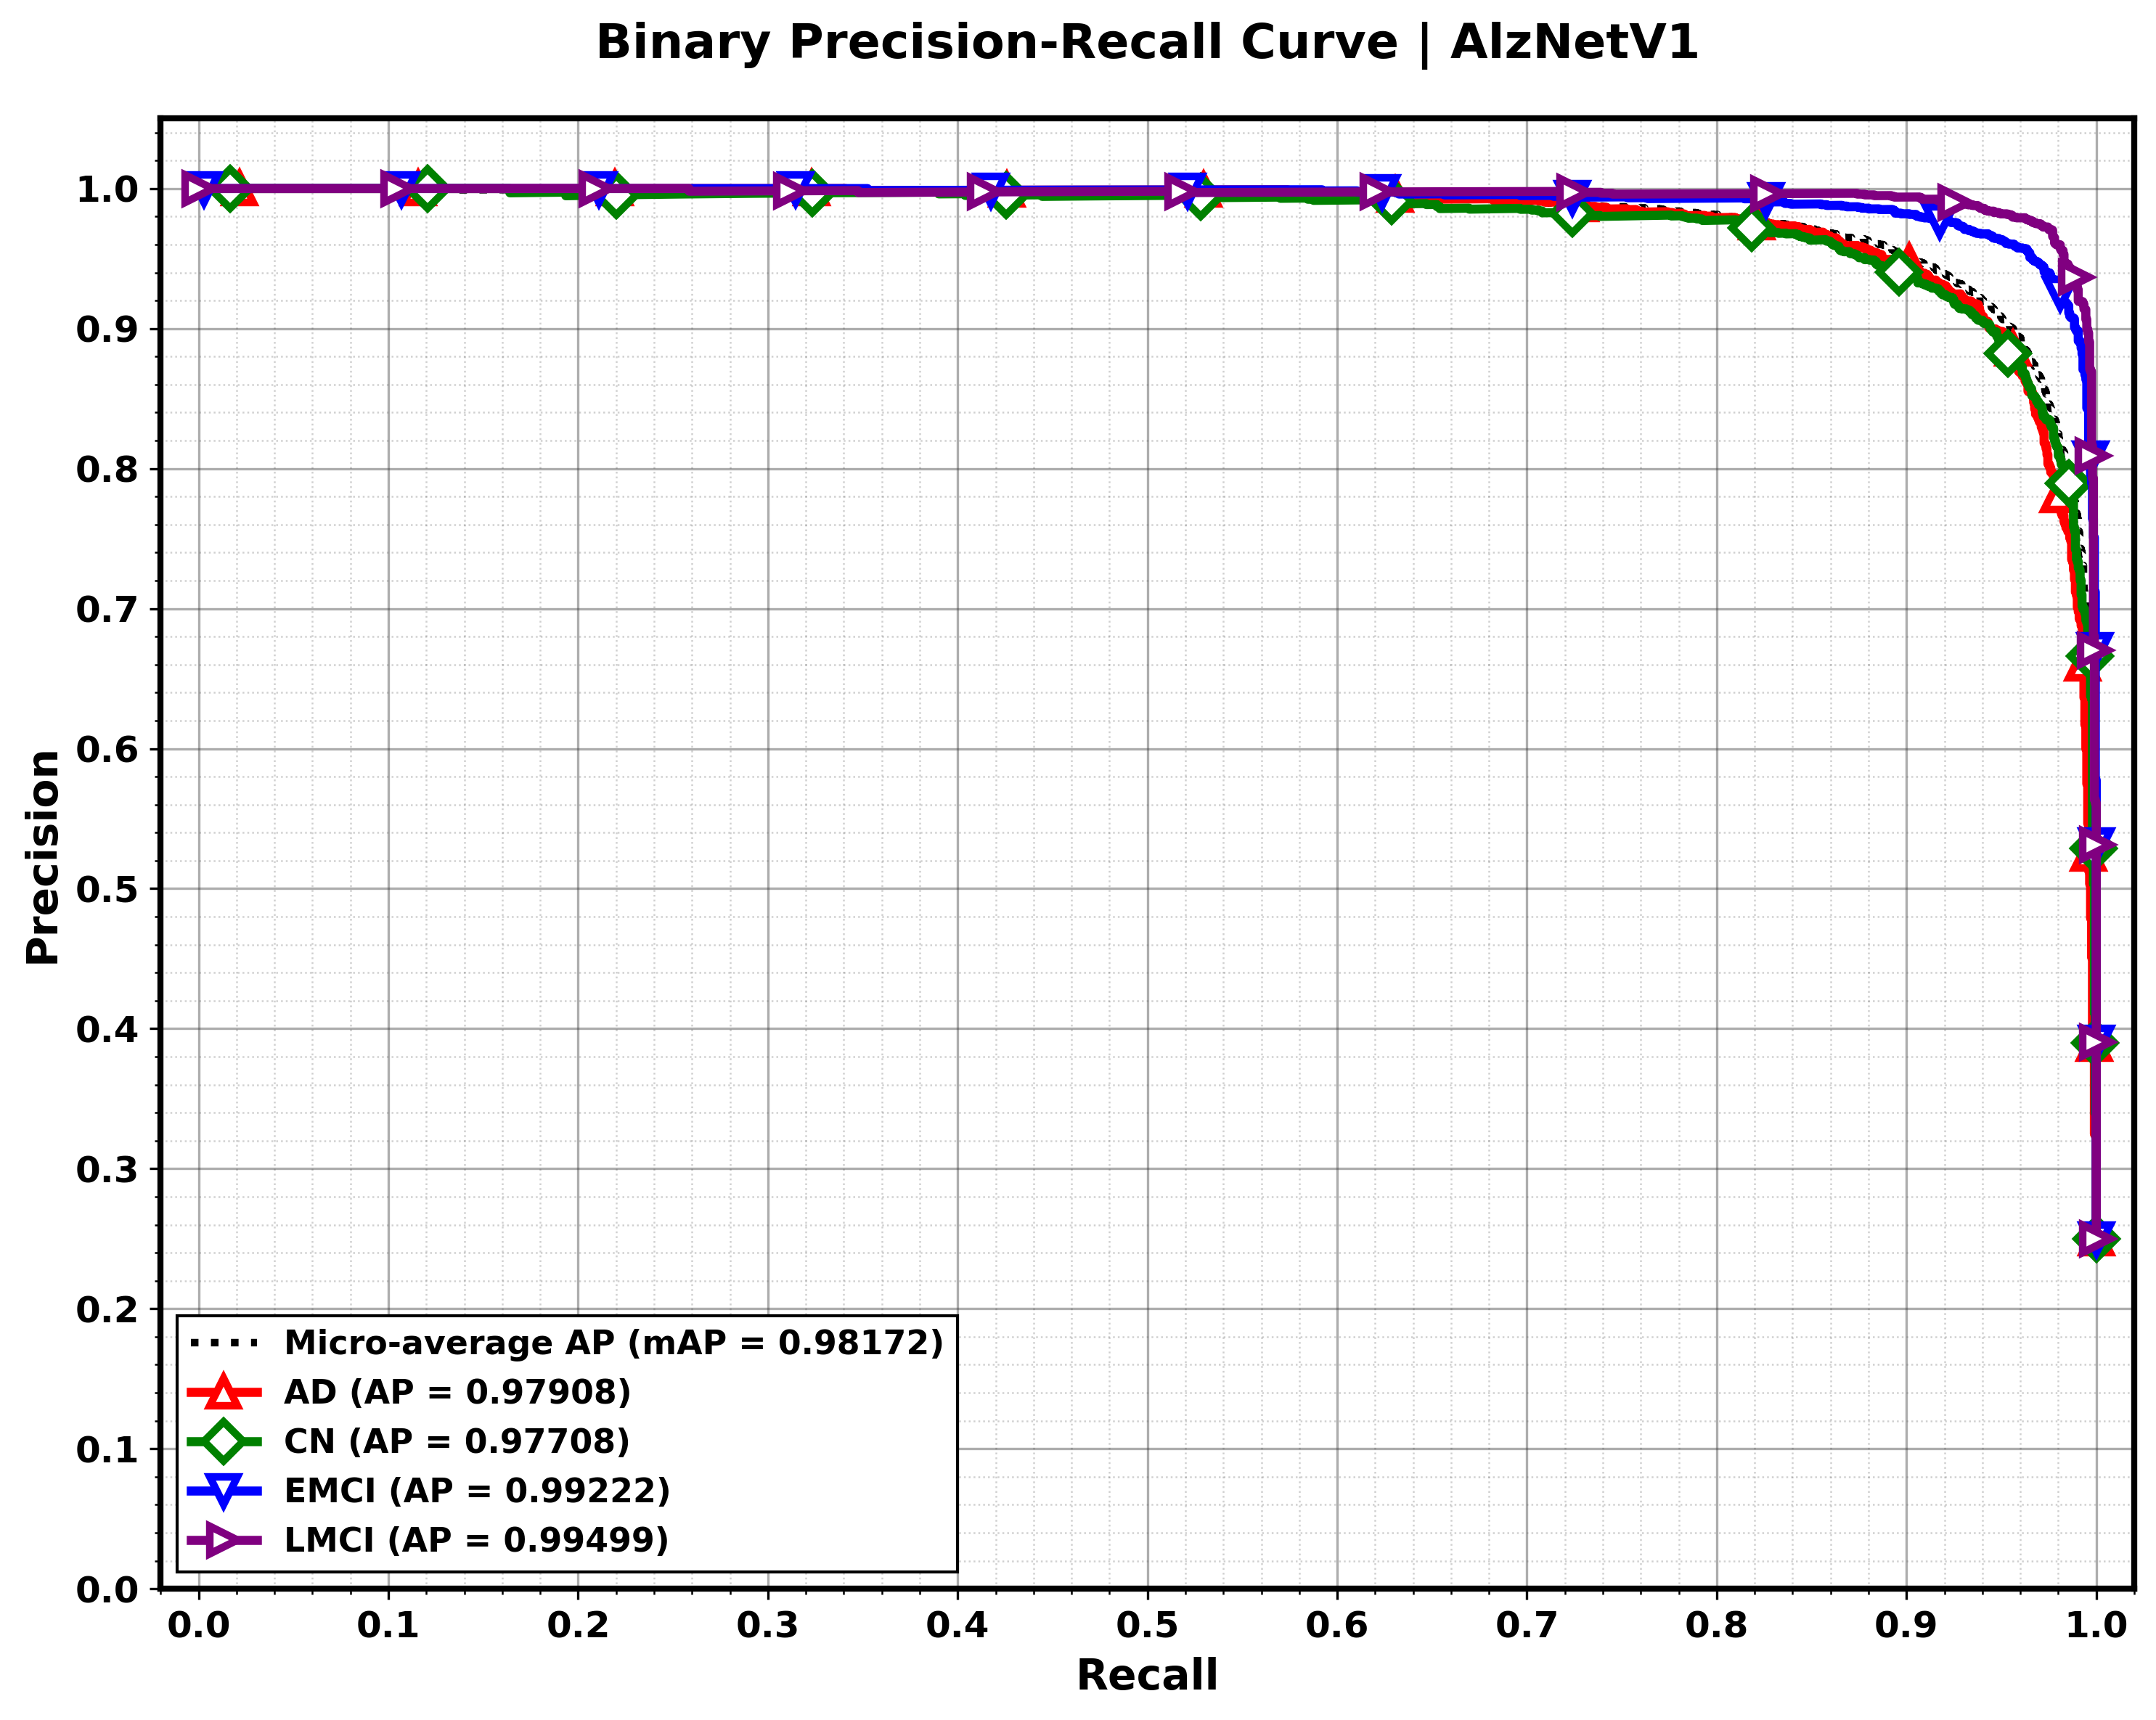

Scientific PR curve saved to: Figures\AlzNetV1\precision_recall_academic.png


In [17]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize

# ==========================================
# 1. SETUP & DATA PREPARATION
# ==========================================
model_name = "AlzNetV1"
base_output_dir = "Figures"
output_folder = os.path.join(base_output_dir, model_name)
os.makedirs(output_folder, exist_ok=True)

# Reset generator and get predictions
validation_generator.reset()
y_pred_prob = model.predict(validation_generator, steps=len(validation_generator))

# Binarize labels for multi-class support
class_indices = validation_generator.class_indices
class_names = list(class_indices.keys())
n_classes = len(class_names)
y_true_bin = label_binarize(validation_generator.classes, classes=np.arange(n_classes))

# ==========================================
# -> FIX FOR TWO CLASSES (BINARY)
# ==========================================
if n_classes == 2:
    # label_binarize outputs (N, 1) for binary, we force it to (N, 2) for the loop
    y_true_bin = np.hstack((1 - y_true_bin, y_true_bin))
    
    # If the model outputs a single probability column (N, 1) via sigmoid
    if y_pred_prob.shape[1] == 1:
        y_pred_prob = np.hstack((1 - y_pred_prob, y_pred_prob))

# ==========================================
# 2. COMPUTE PR & AP SCORES
# ==========================================
precision = dict()
recall = dict()
average_precision = dict()

for i in range(n_classes):
    precision[i], recall[i], _ = precision_recall_curve(y_true_bin[:, i], y_pred_prob[:, i])
    average_precision[i] = average_precision_score(y_true_bin[:, i], y_pred_prob[:, i])

# Compute micro-average (Mean Average Precision - mAP)
precision["micro"], recall["micro"], _ = precision_recall_curve(y_true_bin.ravel(), y_pred_prob.ravel())
average_precision["micro"] = average_precision_score(y_true_bin, y_pred_prob, average="micro")

# ==========================================
# 3. SCIENTIFIC PR PLOTTING (Matched Aesthetic)
# ==========================================
plt.figure(figsize=(10, 8), dpi=300)
plt.style.use('default') 

# 1. COLOR & MARKER PALETTE (Requested: Blue, Green, Red, Yellow, Pink)
custom_colors = ['red', 'green', 'blue', 'purple', 'magenta']
custom_markers = ['^', 'D', 'v', '>', '*'] 

# Plot Micro-average PR Curve (mAP)
plt.plot(recall["micro"], precision["micro"],
         label=f'Micro-average AP (mAP = {average_precision["micro"]:.5f})',
         color='black', linestyle=':', linewidth=2.5)

# Plot each class using the requested palette
for i in range(n_classes):
    color = custom_colors[i % len(custom_colors)]
    marker = custom_markers[i % len(custom_markers)]
    
    plt.plot(recall[i], precision[i], 
             color=color, 
             marker=marker, 
             markevery=0.08,     # Spaced markers for clarity
             markersize=9, 
             markerfacecolor='white', 
             markeredgewidth=2.5,
             lw=3,
             label=f'{class_names[i]} (AP = {average_precision[i]:.5f})')

# --- STYLING TO MATCH REFERENCE BACKGROUND ---

# 2. THE SCIENTIFIC GRID (Dense "Graph Paper" Style)
plt.minorticks_on()
# Major grid: Darker and solid
plt.grid(True, which='major', color='#333333', linestyle='-', alpha=0.4, linewidth=0.8)
# Minor grid: Lighter and dotted
plt.grid(True, which='minor', color='#666666', linestyle=':', alpha=0.3, linewidth=0.6)

# 3. AXIS LIMITS & TICKS
plt.xlim([-0.02, 1.02])
plt.ylim([0.0, 1.05])
plt.xticks(np.arange(0, 1.1, 0.1), fontweight='bold', fontsize=12)
plt.yticks(np.arange(0, 1.1, 0.1), fontweight='bold', fontsize=12)

# 4. THE FRAME (Bold black bounding box)
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('black')
    spine.set_linewidth(2.0)

# 5. LEGEND (Sharp square box with black border)
# Note: Legend for PR curves is usually best in 'lower left' or 'upper right'
plt.legend(loc="lower left", prop={'weight': 'bold', 'size': 11}, 
           frameon=True, edgecolor='black', framealpha=1, fancybox=False)

plt.title(f'Binary Precision-Recall Curve | {model_name}', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Recall', fontsize=14, fontweight='bold')
plt.ylabel('Precision', fontsize=14, fontweight='bold')

plt.tight_layout()

# Save Plot
pr_path = os.path.join(output_folder, "precision_recall_academic.png")
plt.savefig(pr_path, dpi=1000, bbox_inches='tight')
plt.show()

print(f"Scientific PR curve saved to: {pr_path}")

500/500 [==============================] - 107s 213ms/step


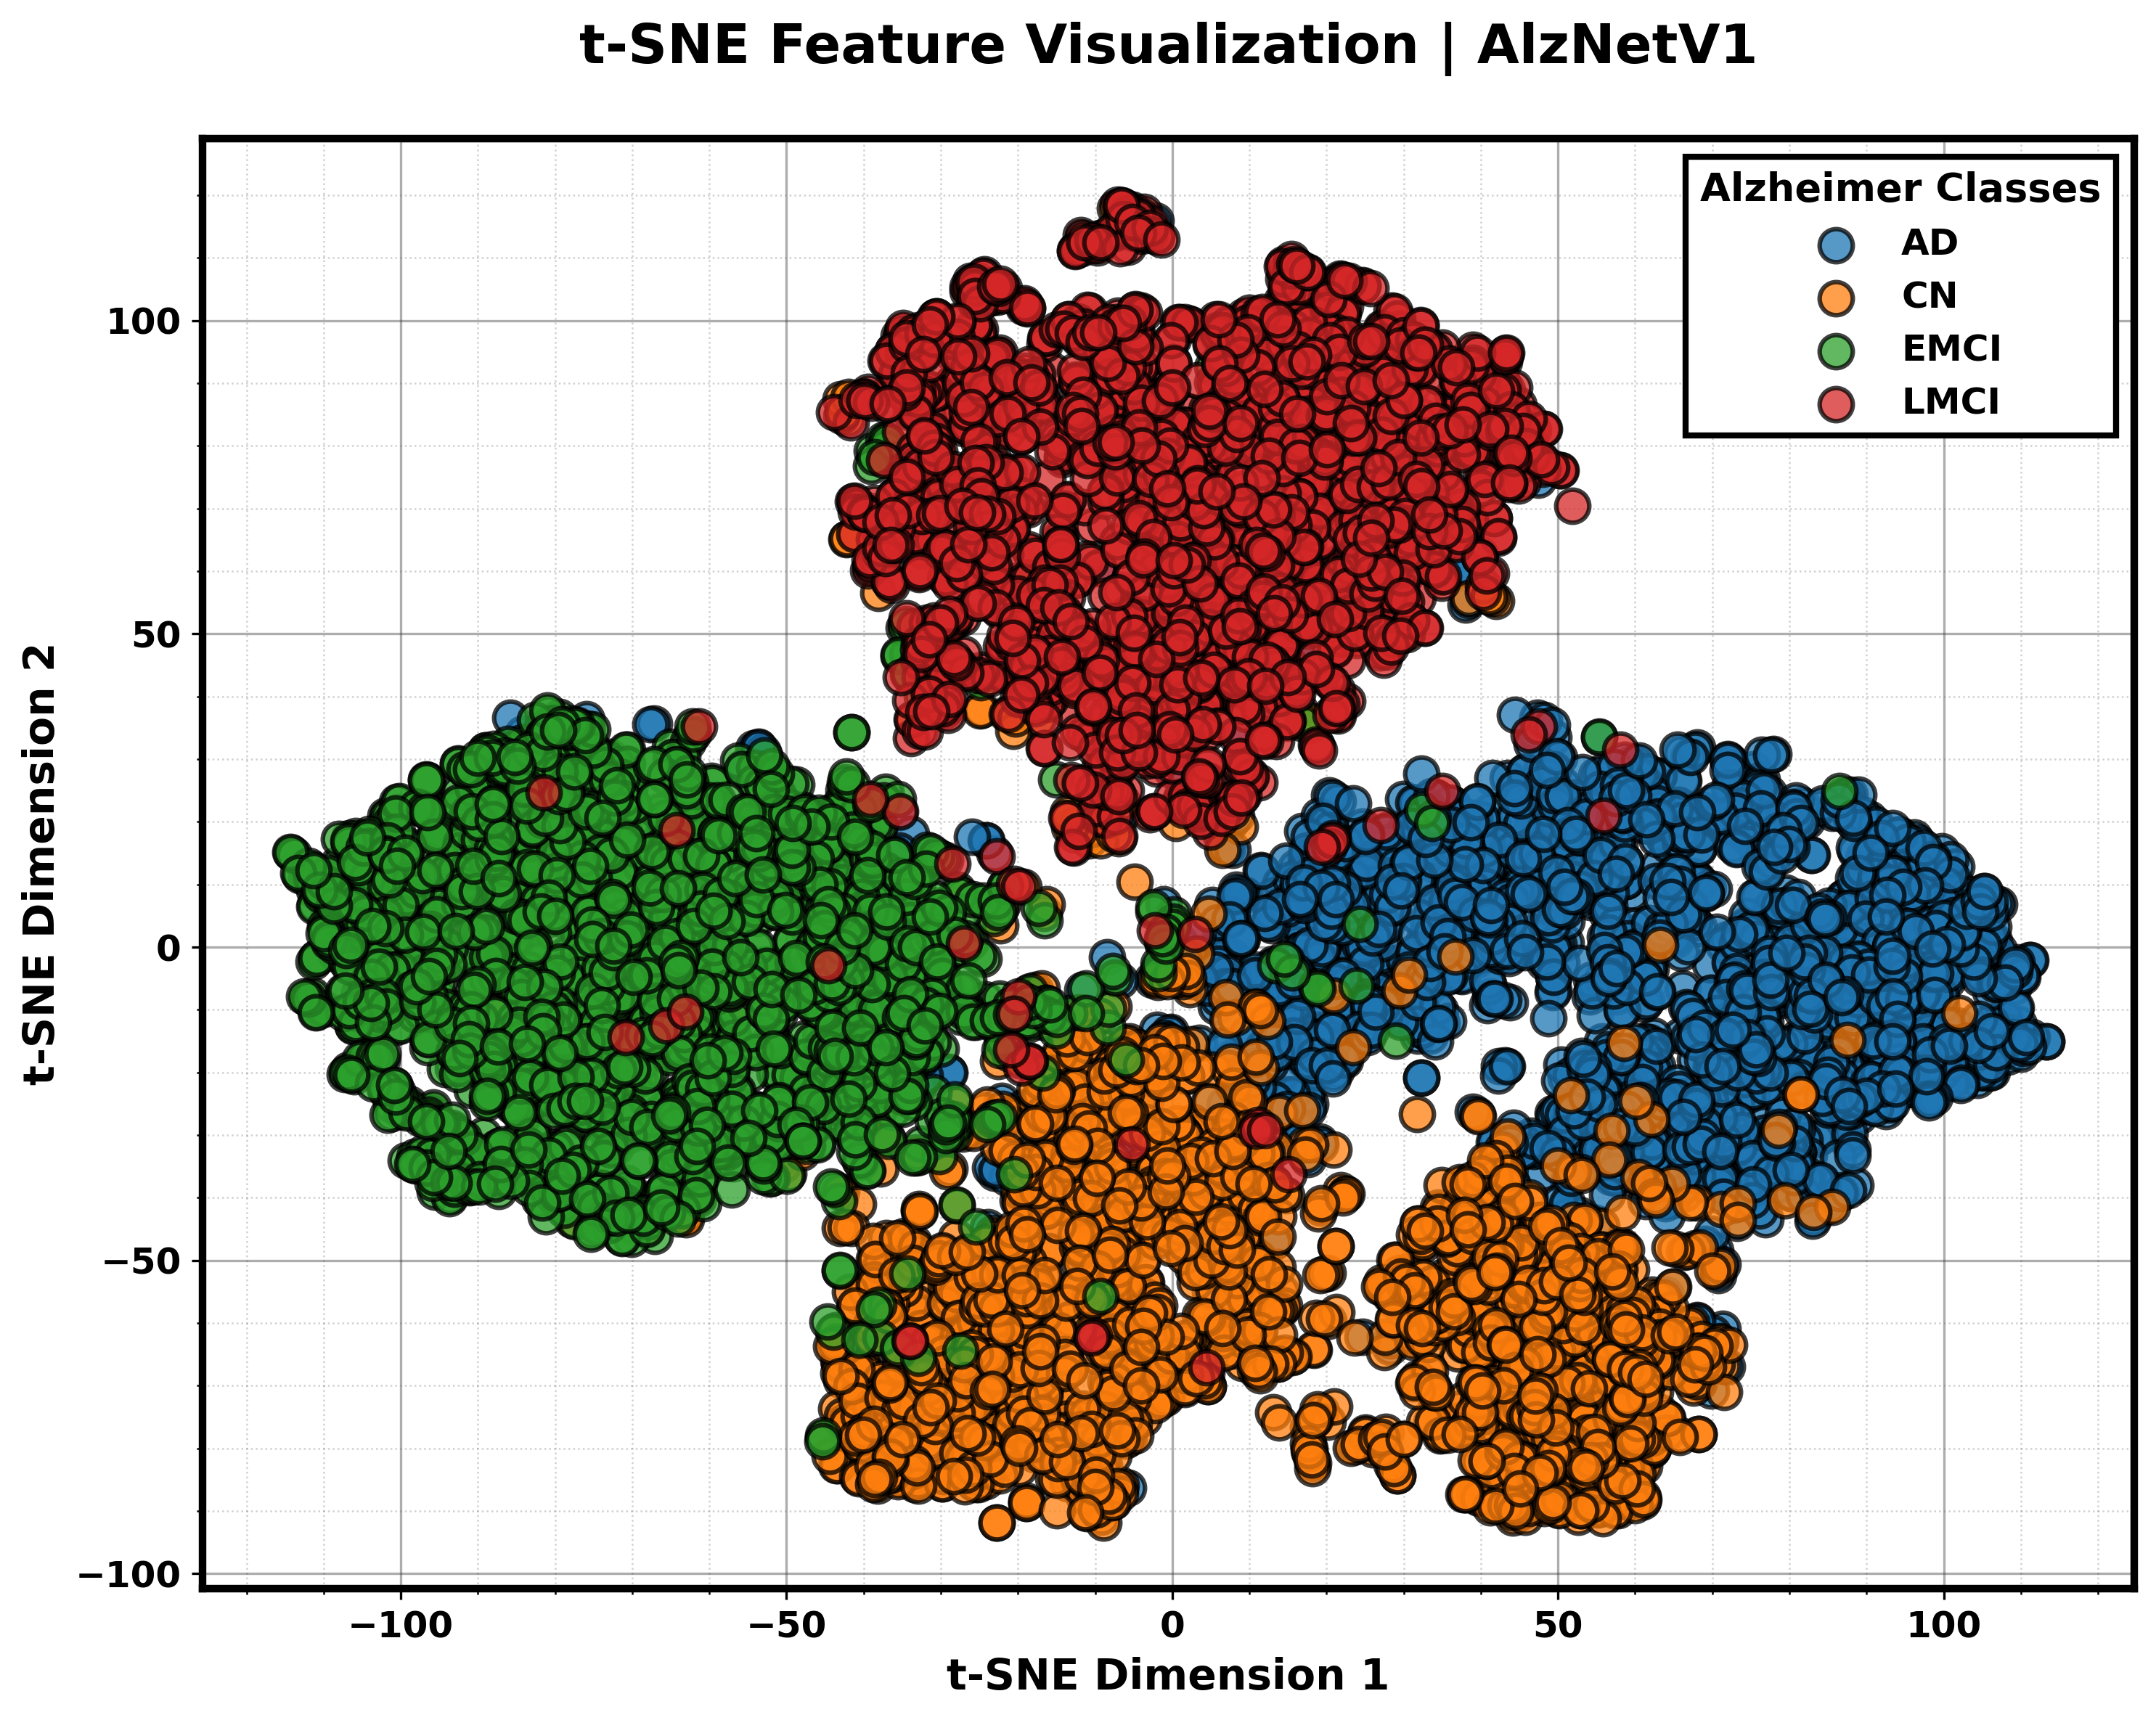

In [18]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from tensorflow.keras.models import Model

# ==========================================
# 1. SETUP & FEATURE EXTRACTION
# ==========================================
model_name = "AlzNetV1"
base_output_dir = "Figures"
output_folder = os.path.join(base_output_dir, model_name)
os.makedirs(output_folder, exist_ok=True)

feature_model = Model(inputs=model.input, outputs=model.layers[-2].output)
validation_generator.reset()
features = feature_model.predict(validation_generator, steps=len(validation_generator))
y_true = validation_generator.classes
class_names = list(validation_generator.class_indices.keys())

# ==========================================
# 2. DIMENSIONALITY REDUCTION
# ==========================================
pca = PCA(n_components=min(50, features.shape[1]))
pca_result = pca.fit_transform(features)

tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=3000, init='pca')
tsne_result = tsne.fit_transform(pca_result)

# ==========================================
# 3. COLOR PALETTE SELECTION (Dynamic)
# ==========================================
n_classes = len(class_names)
if n_classes <= 10:
    palette = sns.color_palette("tab10", n_classes)
elif n_classes <= 20:
    palette = sns.color_palette("tab20", n_classes)
else:
    palette = sns.color_palette("hls", n_classes)

# ==========================================
# 4. SCIENTIFIC t-SNE PLOTTING
# ==========================================
plt.figure(figsize=(10, 8), dpi=300)
plt.style.use('default')

for i, name in enumerate(class_names):
    indices = np.where(y_true == i)
    plt.scatter(
        tsne_result[indices, 0], 
        tsne_result[indices, 1],
        label=name,
        alpha=0.75,          
        s=120,               
        color=palette[i],     # Using the dynamic palette requested
        marker='o',          # Uniform circles
        edgecolors='black',  
        linewidths=1.5,      
        zorder=3 
    )

# --- SCIENTIFIC BACKGROUND STYLING ---
plt.minorticks_on()
plt.grid(True, which='major', color='#333333', linestyle='-', alpha=0.4, linewidth=0.8)
plt.grid(True, which='minor', color='#666666', linestyle=':', alpha=0.3, linewidth=0.6)

# Bold Frame
ax = plt.gca()
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('black')
    spine.set_linewidth(2.5)

# Ultra-Bold Legend
leg = plt.legend(
    title="Alzheimer Classes", 
    prop={'weight': 'black', 'size': 12}, 
    frameon=True, 
    edgecolor='black', 
    fancybox=False,
    framealpha=1.0, 
    loc='best'
)
plt.setp(leg.get_title(), weight='black', size=13)
leg.get_frame().set_linewidth(2.0)

# Labels and Ticks
plt.title(f't-SNE Feature Visualization | {model_name}', fontsize=18, fontweight='black', pad=25)
plt.xlabel('t-SNE Dimension 1', fontsize=14, fontweight='black')
plt.ylabel('t-SNE Dimension 2', fontsize=14, fontweight='black')
plt.xticks(fontweight='black', fontsize=12)
plt.yticks(fontweight='black', fontsize=12)

plt.tight_layout()

# ==========================================
# 5. SAVE & SHOW
# ==========================================
tsne_save_path = os.path.join(output_folder, f'{model_name}_tSNE_Dynamic.png')
plt.savefig(tsne_save_path, dpi=1000, bbox_inches='tight')
plt.show()